# Matplotlib Exercises and Mini Project

## Exercise 1: Retail Sales Trend Analysis

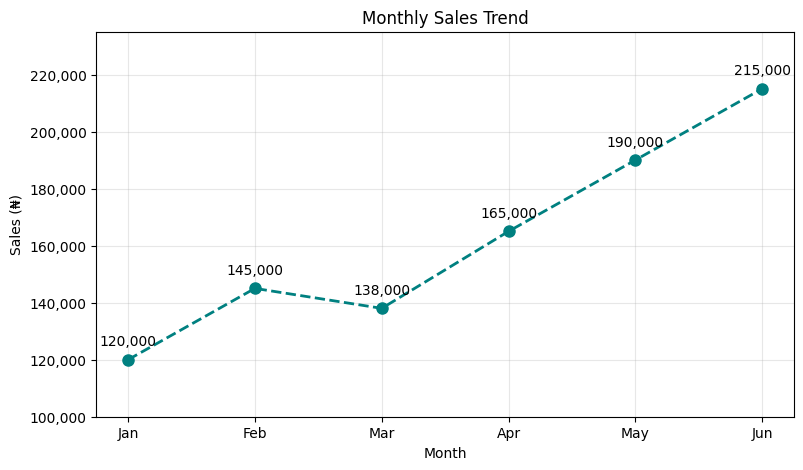

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120000, 145000, 138000, 165000, 190000, 215000]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(months, sales, color="teal", linestyle="--", linewidth=2, marker="o", markersize=8)

for m, s in zip(months, sales):
    ax.annotate(f"{s:,}", (m, s), textcoords="offset points", xytext=(0, 10), ha="center")

ax.set_xlabel("Month")
ax.set_ylabel("Sales (₦)")
ax.set_title("Monthly Sales Trend")
ax.set_ylim(100000, 235000)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(alpha=0.3)

plt.show()

In [2]:
for i in range(1, len(sales)):
    change = sales[i] - sales[i - 1]
    pct = change / sales[i - 1] * 100
    print(f"{months[i - 1]} to {months[i]}: {change:+,} ({pct:+.1f}%)")

total_growth = (sales[-1] - sales[0]) / sales[0] * 100
print(f"January to June growth: {total_growth:.1f}%")

Jan to Feb: +25,000 (+20.8%)
Feb to Mar: -7,000 (-4.8%)
Mar to Apr: +27,000 (+19.6%)
Apr to May: +25,000 (+15.2%)
May to Jun: +25,000 (+13.2%)
January to June growth: 79.2%


### Two observations
1. Sales rose from ₦120,000 in January to ₦215,000 in June, which is growth of about 79%.
2. March is the only month where sales fell, dropping by ₦7,000 from February. Every other month grew, and April, May and June each added about ₦25,000 or more.

### How this helps the business owner
The owner can see at a glance that the business is growing overall and can spot the one month that broke the pattern. That makes March the obvious month to investigate, instead of searching through a table of numbers.

### My reflection
A line chart suits this problem because the months follow a natural order and the question is about change over time. The slope of the line shows growth and decline directly.

Before explaining why sales moved, I would ask for: the number of customers and the average spend per customer each month, any promotions or price changes, stock availability, seasonal events such as holidays, and whether the number of trading days was the same in each month. The chart shows what happened, but not why.

## Exercise 2: Customer Acquisition Comparison

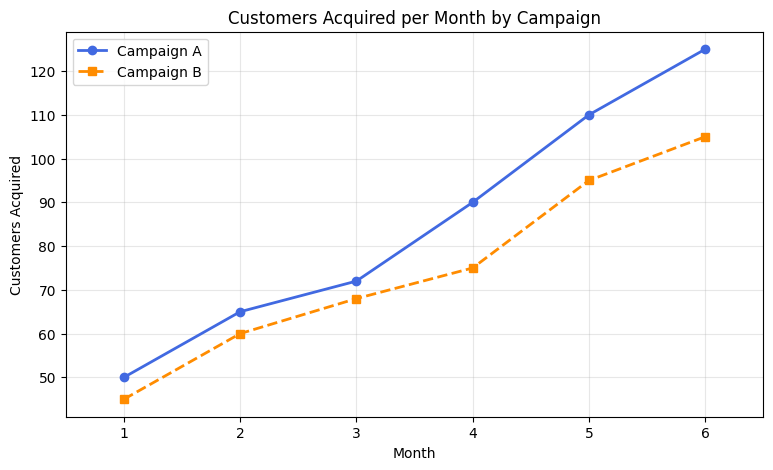

In [3]:
months = [1, 2, 3, 4, 5, 6]
campaign_a = [50, 65, 72, 90, 110, 125]
campaign_b = [45, 60, 68, 75, 95, 105]

plt.figure(figsize=(9, 5))
plt.plot(months, campaign_a, color="royalblue", linestyle="-", marker="o", linewidth=2, label="Campaign A")
plt.plot(months, campaign_b, color="darkorange", linestyle="--", marker="s", linewidth=2, label="Campaign B")

plt.xlabel("Month")
plt.ylabel("Customers Acquired")
plt.title("Customers Acquired per Month by Campaign")
plt.xticks(months)
plt.xlim(0.5, 6.5)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [4]:
gap = [a - b for a, b in zip(campaign_a, campaign_b)]
print("Monthly gap (A minus B):", gap)
print("Total customers, Campaign A:", sum(campaign_a))
print("Total customers, Campaign B:", sum(campaign_b))
print(f"Growth from month 1 to 6, A: {(campaign_a[-1] - campaign_a[0]) / campaign_a[0] * 100:.0f}%")
print(f"Growth from month 1 to 6, B: {(campaign_b[-1] - campaign_b[0]) / campaign_b[0] * 100:.0f}%")

Monthly gap (A minus B): [5, 5, 4, 15, 15, 20]
Total customers, Campaign A: 512
Total customers, Campaign B: 448
Growth from month 1 to 6, A: 150%
Growth from month 1 to 6, B: 133%


### Observations
1. Campaign A acquired more customers than Campaign B in every one of the six months.
2. The gap between them widened. It was 5 customers in month 1 and 20 customers in month 6, with a clear jump from 4 in month 3 to 15 in month 4.
3. Both campaigns grew strongly. Campaign A grew by 150% (50 to 125) and Campaign B by about 133% (45 to 105). Over the six months Campaign A brought in 512 customers against 448 for Campaign B.

### Bonus: Separate subplots

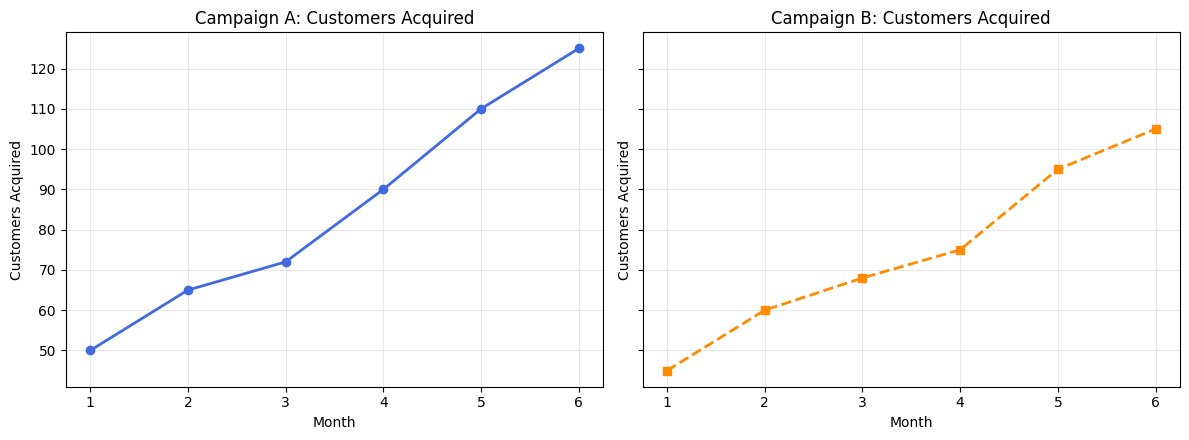

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

axes[0].plot(months, campaign_a, color="royalblue", marker="o", linewidth=2)
axes[0].set_title("Campaign A: Customers Acquired")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Customers Acquired")
axes[0].set_xticks(months)
axes[0].grid(alpha=0.3)

axes[1].plot(months, campaign_b, color="darkorange", linestyle="--", marker="s", linewidth=2)
axes[1].set_title("Campaign B: Customers Acquired")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Customers Acquired")
axes[1].set_xticks(months)
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

I used `sharey=True` so both charts use the same y-axis scale. Without it, the two charts could look similar even when the numbers differ, which would make the comparison misleading.

### My reflection
The chart cannot fully answer which campaign deserves more money. It shows that Campaign A acquires more customers, but it says nothing about cost or about the quality of the customers.

Two pieces of information I would need:
1. **Cost per campaign.** If Campaign A cost twice as much as Campaign B, then cost per customer acquired could favour B even though A brings in more people.
2. **Customer value.** I would want to know how much each acquired customer spends and how long they stay, because a campaign that brings fewer but more loyal customers can be worth more.

I would also check whether the two campaigns targeted the same kind of audience and ran under the same conditions. The chart shows a pattern, but it does not prove that the campaign itself caused the result.

## Exercise 3: Healthcare Performance Dashboard

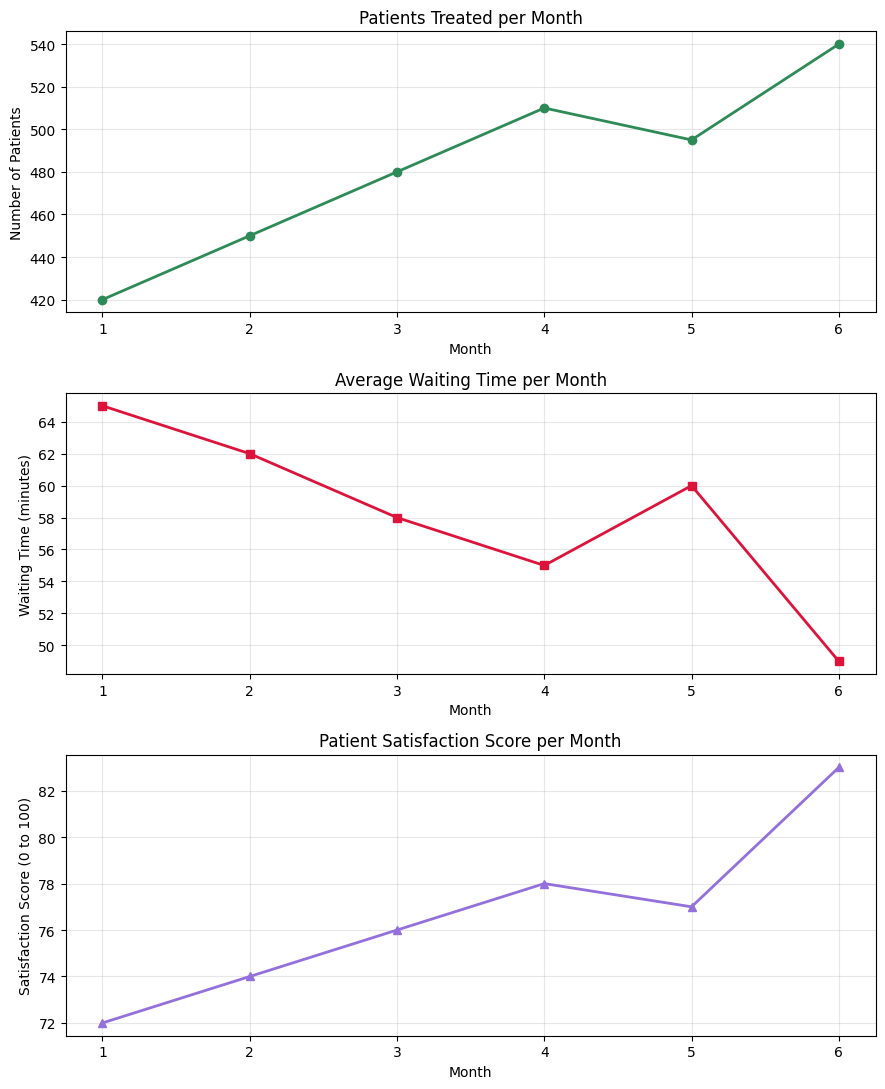

In [6]:
months = [1, 2, 3, 4, 5, 6]
patients = [420, 450, 480, 510, 495, 540]
waiting_time = [65, 62, 58, 55, 60, 49]
satisfaction = [72, 74, 76, 78, 77, 83]

fig, axes = plt.subplots(3, 1, figsize=(9, 11))

axes[0].plot(months, patients, color="seagreen", marker="o", linewidth=2)
axes[0].set_title("Patients Treated per Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Patients")

axes[1].plot(months, waiting_time, color="crimson", marker="s", linewidth=2)
axes[1].set_title("Average Waiting Time per Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Waiting Time (minutes)")

axes[2].plot(months, satisfaction, color="mediumpurple", marker="^", linewidth=2)
axes[2].set_title("Patient Satisfaction Score per Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Satisfaction Score (0 to 100)")

for ax in axes:
    ax.set_xticks(months)
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

### Report
**Patient volume** rose from 420 to 540 patients, an increase of about 29%. It grew steadily until month 4 (510), dipped slightly in month 5 (495), then reached its highest level in month 6.

**Average waiting time** fell from 65 minutes to 49 minutes, a drop of 16 minutes. It improved every month except month 5, when it rose from 55 to 60 minutes before falling to its lowest point in month 6.

**Patient satisfaction** rose from 72 to 83. It also dipped slightly in month 5 (78 to 77) and then jumped by 6 points in month 6, reaching its highest score.

Month 5 stands out because patient volume, waiting time and satisfaction all moved in the less favourable direction together. Month 6 shows the opposite, with the best result on all three. These are observed patterns only. The data does not tell us what happened inside the hospital in those months.

### Bonus: Think like a healthcare analyst

**Why not plot all three on one y-axis?** The three indicators use different units and scales. Patients are counted in hundreds, waiting time is in minutes and satisfaction is a score out of 100. On one axis, the patient line would sit around 400 to 540 while the other two sit between 49 and 83. The smaller series would look nearly flat and their month to month changes would be hard to see, even though they changed meaningfully. The visual size of a change would then reflect the unit chosen, not the importance of the change.

**What happened to patient volume?** It increased from 420 to 540, with one dip in month 5.

**How did waiting time change?** It decreased from 65 to 49 minutes, with one increase in month 5.

**What happened to satisfaction in the final month?** It rose from 77 to 83, the largest monthly increase in the series and the highest score recorded.

**Do the patterns prove shorter waits caused higher satisfaction?** No. The two series do move in opposite directions, and the correlation below is strongly negative, but correlation is not causation. Other things changed at the same time, such as patient volume, staffing, treatment quality or the type of patients seen. With only six data points, any relationship is also very uncertain.

In [7]:
import numpy as np

print("Waiting time vs satisfaction:", round(np.corrcoef(waiting_time, satisfaction)[0, 1], 3))

Waiting time vs satisfaction: -0.974


**What additional data would help?**
1. Patient level data, so waiting time and satisfaction can be compared for the same patients instead of monthly averages.
2. Staffing levels, number of doctors and nurses on duty, and bed availability.
3. Satisfaction survey details, including how many patients responded and what questions were asked.
4. A longer time period, so one unusual month does not drive the conclusion.
5. Other satisfaction drivers, such as treatment outcomes, cost, cleanliness and staff behaviour.

### My reflection
One chart cannot decide whether the hospital is succeeding. What I can do is describe what the numbers show, point out month 5 as worth investigating, and suggest questions management should ask next.

## Mini Project: Visualizing Business Performance with Matplotlib

### Business problem
A small business owner wants a simple Python based report on revenue, customer growth and product performance over six months.

### Dataset
Six months of data: monthly revenue in naira, number of customers recorded, and units sold for Product A and Product B. Product values are assumed to be units sold.

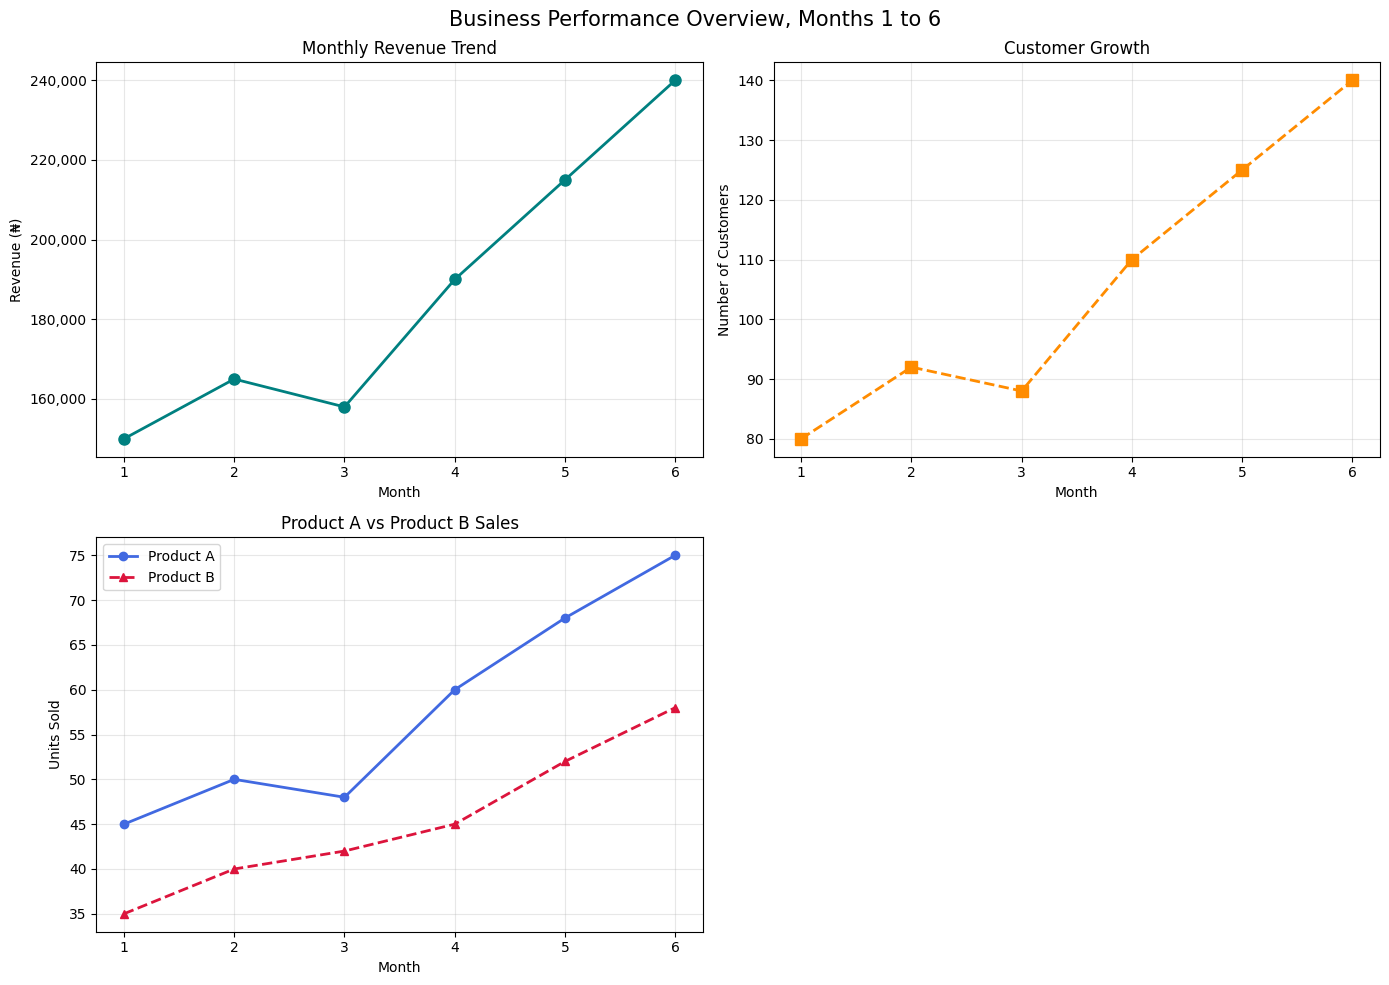

In [8]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

months = [1, 2, 3, 4, 5, 6]
revenue = [150000, 165000, 158000, 190000, 215000, 240000]
customers = [80, 92, 88, 110, 125, 140]
product_a = [45, 50, 48, 60, 68, 75]
product_b = [35, 40, 42, 45, 52, 58]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(months, revenue, color="teal", linestyle="-", linewidth=2, marker="o", markersize=8)
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue (₦)")
axes[0, 0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

axes[0, 1].plot(months, customers, color="darkorange", linestyle="--", linewidth=2, marker="s", markersize=8)
axes[0, 1].set_title("Customer Growth")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Number of Customers")

axes[1, 0].plot(months, product_a, color="royalblue", linestyle="-", linewidth=2, marker="o", label="Product A")
axes[1, 0].plot(months, product_b, color="crimson", linestyle="--", linewidth=2, marker="^", label="Product B")
axes[1, 0].set_title("Product A vs Product B Sales")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Units Sold")
axes[1, 0].legend()

axes[1, 1].axis("off")

for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.set_xticks(months)
    ax.grid(alpha=0.3)

fig.suptitle("Business Performance Overview, Months 1 to 6", fontsize=15)
fig.tight_layout()

os.makedirs("images", exist_ok=True)
fig.savefig("images/business_performance_charts.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
print("Month to month revenue change:")
for i in range(1, len(revenue)):
    print(f"  Month {i} to {i + 1}: {revenue[i] - revenue[i - 1]:+,}")

print("Month to month customer change:")
for i in range(1, len(customers)):
    print(f"  Month {i} to {i + 1}: {customers[i] - customers[i - 1]:+}")

print("Revenue per customer by month:", [round(r / c) for r, c in zip(revenue, customers)])
print(f"Revenue growth: {(revenue[-1] - revenue[0]) / revenue[0] * 100:.0f}%")
print(f"Customer growth: {(customers[-1] - customers[0]) / customers[0] * 100:.0f}%")
print("Month 6 units sold, Product A:", product_a[-1], "Product B:", product_b[-1])

Month to month revenue change:
  Month 1 to 2: +15,000
  Month 2 to 3: -7,000
  Month 3 to 4: +32,000
  Month 4 to 5: +25,000
  Month 5 to 6: +25,000
Month to month customer change:
  Month 1 to 2: +12
  Month 2 to 3: -4
  Month 3 to 4: +22
  Month 4 to 5: +15
  Month 5 to 6: +15
Revenue per customer by month: [1875, 1793, 1795, 1727, 1720, 1714]
Revenue growth: 60%
Customer growth: 75%
Month 6 units sold, Product A: 75 Product B: 58


### Business report: key observations

1. **Revenue grew strongly overall.** Revenue rose from ₦150,000 in month 1 to ₦240,000 in month 6, an increase of 60%. The only decline was in month 3, when revenue fell by ₦7,000 compared with month 2.

2. **Customers followed the same pattern as revenue.** Customer numbers grew from 80 to 140, an increase of 75%, and also fell only in month 3 (from 92 to 88). Revenue and customers moved in the same direction in every month, so there is no month where they diverged.

3. **Customers grew faster than revenue.** Because customers grew by 75% and revenue by 60%, revenue per customer fell from about ₦1,875 in month 1 to about ₦1,714 in month 6. The business is gaining customers, but each customer is contributing slightly less revenue on average.

4. **Product A outsold Product B in the final month.** Product A sold 75 units and Product B sold 58 units in month 6. Product A led in every month, but Product B grew steadily and even rose in month 3 (40 to 42) while Product A fell (50 to 48).

### What the data shows and what might explain it
The data shows the patterns above. It does not show why they happened. The month 3 dip could be linked to seasonality, stock problems or a change in marketing, but I cannot confirm any of these from this dataset. The fall in revenue per customer could mean customers are buying cheaper items, getting discounts, or that new customers spend less at first. That also needs to be checked.

### Information that would help the owner
1. Prices and discounts, to explain the drop in revenue per customer.
2. Marketing activity by month, to see what may have driven customer growth.
3. Revenue by product, since units sold do not show how much money each product earns.
4. Whether customers are new or returning.
5. Stock levels, in case supply limits affected month 3.
6. More months of data, to tell a real trend from a short term movement.

### Tools used
Python, Matplotlib, Jupyter Notebook.

### How to run
Open this notebook in Jupyter or Google Colab, then use Run All. The final figure is saved to `images/business_performance_charts.png`.